# Hierarchical visual search

**Recipe 83 · Level 4 (Advanced) · `Choice` + `Box`**

## What you will build

Find a small marker in an authored 1024 × 768 workbench diagram. Python divides the image into overlapping tiles; one fixed-option `Choice` selects a tile at each of two levels. A later `Box` localizes the marker inside the final crop. Python maps its coordinates back to the full image and records only a simulated rectangle.

A [typed answer](../../docs/glossary.md#question) has a defined structure. Here `Choice` returns an option and probabilities; `Box` returns one normalized rectangle and optional confidence. **Box always returns coordinates even when the object is absent.** Presence is therefore a separate decision, and ambiguity leads to review.

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S10: [Box](https://docs.typesafe.ai/primitives/box)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

Images and Box are experimental; live mode pins `jev-1.14.0` and enables the image header.

## Setup and run mode

The default [replay backend](../../docs/glossary.md#fixture) uses synthetic answers: no model, network, or API key takes part. Ten validation scenes select the overlap policy and confidence gate; ten held-out test scenes compare the frozen hierarchy with a full-image baseline. Two additional scenes illustrate the answers without entering evaluation.

The notebook requires Pillow and the shared package. `RequestCache` reuses identical requests during validation sweeps. A request with changed pixels has a different [replay key](../../docs/glossary.md#replay-key); a missing fixture raises an error. Live setup and adaptive recording are in the README.

In [1]:
import json

from IPython.display import display
from matplotlib.figure import Figure

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, run_header, show_answer
from jev_cookbook.vision import draw_boxes, normalized_to_pixels

apply_style()
helpers = load_helpers()
examples, labels = load_inputs(), load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
cache = helpers.RequestCache(backend)
scored = [example for example in examples if example.split != "demo"]
check = " (a pipeline check, not a Jev result)" if backend.mode in ("synthetic", "scripted") else ""
if backend.mode == "live":
    check = " (unrecorded live diagnostic; not a reportable result)"
selection = " (a selection step, not a reported result)"
run_header(83, "Hierarchical visual search", backend=backend, n_examples=len(scored))

Recipe 83: Hierarchical visual search
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 20 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Each scene contains neutral clutter, blue plus markers, pink circles, and pink squares with diagonal marks. The target is a pink square with a white plus. Some scenes place it near seams or image edges; others contain no target, two matching targets, or a tiny target among distractors. These are diagrams drawn with Pillow, not photographs or scraped images.

Only pixels and the fixed target description enter the request. The scene filename, split, authored response specification, and [gold label](../../docs/glossary.md#gold-label) stay in Python. Gold means the independent expected outcome used during evaluation, including a full-image rectangle for uniquely present targets.

Requested object: the small pink square marker with a white plus sign in its center; exclude blue squares, pink circles, and pink squares with a dark diagonal
Original image size: (1024, 768)


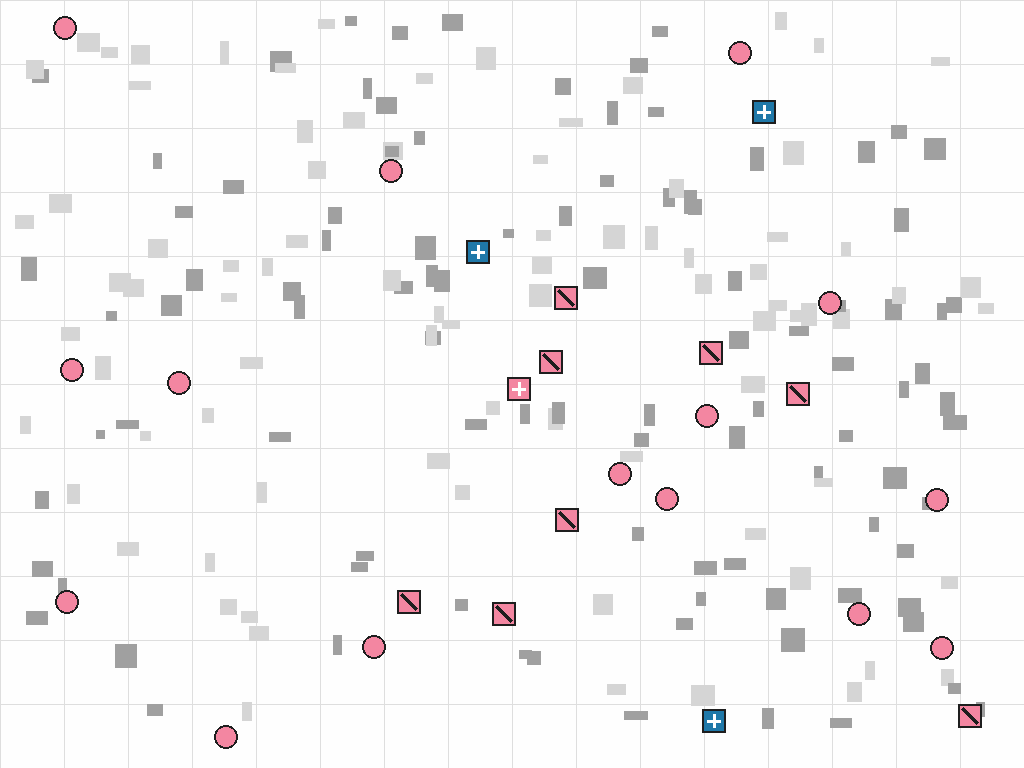

In [2]:
demo = next(example for example in examples if example.id == "d01")
root = helpers.load_view(demo.fields)
print("Requested object:", helpers.TARGET)
print("Original image size:", root.image.size)
display(root.image)

## The questions

The four tile options are built in row-major order. Their descriptions carry image references, so the semantic evidence is the crop itself. `none` and `uncertain` are explicit options. Overlap can show the same marker twice: the instruction selects the first crop containing it completely; multiple distinct matches require `uncertain`. There is no gold tile ID to match.

Each level depends on the previous answer and therefore uses a later request. The final `Box` is another later request, after both tile choices pass. The `compact` policy adds 64 pixels to each half-image dimension; `wide` adds 128. This produces overlaps of 128 and 256 pixels, respectively. After two levels, crops are 352 × 288 or 448 × 384, above the documented image dimension and area minima. We demonstrate `wide` here; validation below makes the final choice.

State: {'target': 'the small pink square marker with a white plus sign in its center; exclude blue squares, pink circles, and pink squares with a dark diagonal'}
Fixed options: ['tile_0', 'tile_1', 'tile_2', 'tile_3', 'none', 'uncertain']
Tile dimensions: [(640, 512), (640, 512), (640, 512), (640, 512)]


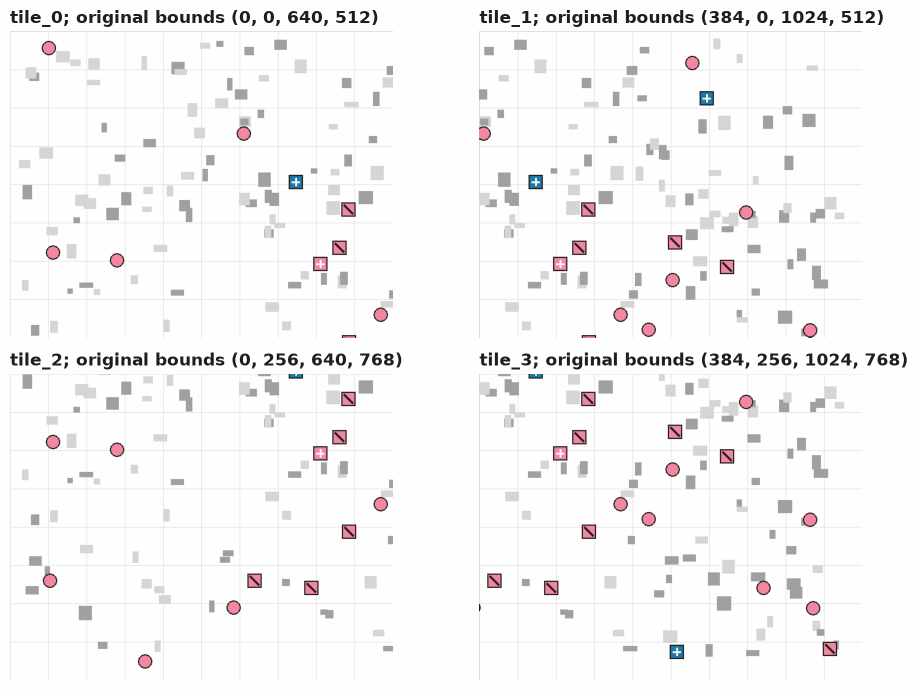

In [3]:
views = helpers.split_view(root, "wide")
state, questions, assets = helpers.tile_request(views)
print("State:", state)
print("Fixed options:", list(questions["tile"].criteria))
print("Tile dimensions:", [view.image.size for view in views])
figure = Figure(figsize=(10, 7))
for index, (axis, view) in enumerate(zip(figure.subplots(2, 2).flat, views, strict=True)):
    axis.imshow(view.image)
    axis.set_title(f"tile_{index}; original bounds {view.bounds}")
    axis.set_axis_off()
figure.tight_layout()
display(figure)

## One answer up close

The following are the actual typed replay answers used for this demonstration. Choice confidence is derived from its probability distribution; it is not simply the top probability. Box confidence is separate and may be unavailable. Neither quantity proves that a selected tile contains the target.

The displayed rectangle is the model-shaped answer mapped through the actual crop bounds. It is not a gold overlay.

Stage: tile
Choice: tile_0 (confidence 0.95)
  tile_0     0.96  ###################
  tile_1     0.01  
  tile_2     0.01  
  tile_3     0.01  
  none       0.01  
  uncertain  0.01  
Provenance: synthetic
Stage: tile
Choice: tile_3 (confidence 0.95)
  tile_3     0.96  ###################
  tile_0     0.01  
  tile_1     0.01  
  tile_2     0.01  
  none       0.01  
  uncertain  0.01  
Provenance: synthetic
Stage: box
Box: normalized coordinates (confidence 0.95)
  top=0.65, bottom=0.71, left=0.70, right=0.76
Provenance: synthetic
Outcome: localized simulated_rectangle_only
Final crop bounds in the original image: (192, 128, 640, 512)
Returned normalized full-image rectangle: {'top': 0.4908854166666667, 'bottom': 0.5221354166666666, 'left': 0.4951171875, 'right': 0.5185546875}
Enclosing original pixel bounds: (507, 377, 531, 401)


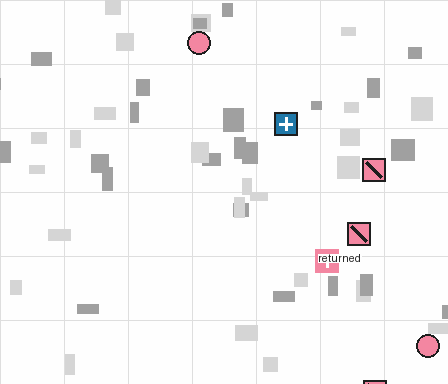

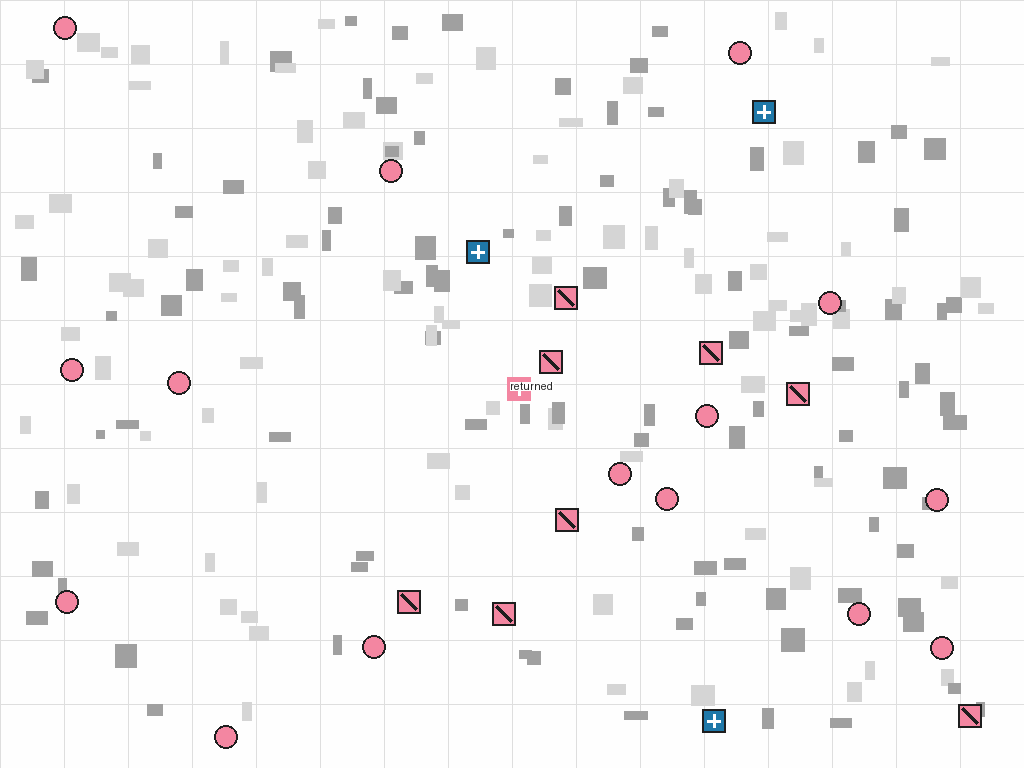

In [4]:
demonstration = helpers.search(cache, root, policy="wide", gate=0.7)
for step in demonstration.trace:
    print("Stage:", step["stage"])
    show_answer(step["answer"])
print("Outcome:", demonstration.status, demonstration.reason)
if demonstration.box is not None:
    final_view = demonstration.trace[-1]["view"]
    print("Final crop bounds in the original image:", final_view.bounds)
    print("Returned normalized full-image rectangle:", demonstration.box)
    print(
        "Enclosing original pixel bounds:",
        normalized_to_pixels(demonstration.box, *root.image.size),
    )
    display(draw_boxes(final_view.image, {"returned": demonstration.trace[-1]["answer"].box}))
    display(draw_boxes(root.image, {"returned": demonstration.box}))

## Python's part

For a final crop `(x₀, y₀, x₁, y₁)` and crop-normalized coordinate `(u, v)`, Python computes `x = x₀ + u × (x₁ − x₀)` and `y = y₀ + v × (y₁ − y₀)`. Both levels accumulate actual integer crop origins, including overlaps. Float coordinates remain unchanged for IoU; floor/ceil rounding is only for enclosing pixels and drawing.

Python enforces the maximum depth, three-request hierarchy budget, confidence gate, finite ordered bounds, and a 96-pixel maximum marker width and height. The marker size rule is fixed from the authored scene specification, before validation. Missing Box confidence always leads to review. There is no retry or search of sibling branches; deeper `none` means the selected branch failed and leads to review, since discarded tiles may contain the target. Root `none` is a complete absent outcome, gated like any other Choice. `uncertain` always enters the [review queue](../../docs/glossary.md#review).

The presence gate prevents a Box call when the answer is absent or uncertain; it cannot guarantee that a confidently wrong presence answer is correct. A small, valid, high-confidence rectangle can still be wrong. Gold never blocks an action. The [action log](../../docs/simulation.md#reviewqueue-and-actionlog) below records a simulated drawing only; no external system changes.

In [5]:
actions, reviews = ActionLog(), ReviewQueue()
helpers.record_outcome(demo.id, demonstration, actions, reviews)
absent_demo = next(example for example in examples if example.id == "d02")
absent_result = helpers.search(
    cache, helpers.load_view(absent_demo.fields), policy="wide", gate=0.7
)
helpers.record_outcome(absent_demo.id, absent_result, actions, reviews)
print("Absent demo:", absent_result.status, "calls:", absent_result.calls)
print("Simulated actions:", json.dumps(actions.to_dicts(), indent=2))
print("Review queue:", reviews.to_dicts())

Absent demo: absent calls: 1
Simulated actions: [
  {
    "seq": 0,
    "kind": "draw_rectangle",
    "payload": {
      "id": "d01",
      "box": {
        "top": 0.4908854166666667,
        "bottom": 0.5221354166666666,
        "left": 0.4951171875,
        "right": 0.5185546875
      }
    },
    "step": null,
    "answer": null,
    "rule": "accepted choices and box; geometry and request limits passed",
    "executed": false
  }
]
Review queue: []


## Evaluation

[Validation](../../docs/fixtures.md#splits) selects the policy; [test](../../docs/fixtures.md#splits) is evaluated once after it is frozen. The hierarchy considers two tile policies and confidence gates `0.4`, `0.7`, and `0.9`. Its objective is **hits − 2 × wrong accepted outcomes**, then fewer logical calls, a higher gate, and `compact` in that order. The direct baseline uses its own gate selected with the same objective on the same validation scenes. These weights and candidate settings were fixed before looking at test outcomes.

An end-to-end hit means IoU ≥ 0.5 for a present target, an explicit absent result for an absent target, or review for a gold ambiguous scene. IoU is intersection area divided by union area. Mean IoU covers every uniquely present target, assigning zero when no rectangle is delivered. Incorrect delivered rectangles retain their measured IoU, even below the 0.5 hit threshold; no easy-case denominator hides failed routing. [Coverage](../../docs/glossary.md#coverage) excludes every review, including correct ambiguity handling. Accepted risk is the fraction of accepted outcomes that are wrong. `evaluate_outcomes` measures the actual routed decisions. Every printed N is the number of scenes, not the number of tile questions.

Calls count the logical path for each method, including presence decisions. They are a structural comparison, not token usage, latency, or cost. Validation caching reduces actual backend requests across candidate policies without changing each candidate's logical path count.

In [6]:
validation = select_split(examples, "validation")
frozen, validation_rows = helpers.select_policy(
    cache,
    validation,
    labels,
    objective="hits - 2 * wrong_accepted; ties: fewer_calls, higher_gate, compact",
)
baseline_gate, baseline_validation_rows = helpers.select_direct_gate(cache, validation, labels)
for row in validation_rows:
    row = {
        key: round(value, 3) if isinstance(value, float) else value for key, value in row.items()
    }
    print(f"Hierarchy validation N={row['n']}{selection}{check}: {row}")
for row in baseline_validation_rows:
    row = {
        key: round(value, 3) if isinstance(value, float) else value for key, value in row.items()
    }
    print(f"Direct validation N={row['n']}{selection}{check}: {row}")
print(f"Frozen hierarchy (policy, gate), N={len(validation)}{selection}{check}:", frozen)
print(f"Frozen direct gate, N={len(validation)}{selection}{check}:", baseline_gate)

Hierarchy validation N=10 (a selection step, not a reported result) (a pipeline check, not a Jev result): {'policy': 'compact', 'gate': 0.4, 'n': 10, 'hits': 5, 'end_to_end_hit': 0.5, 'mean_iou_all_present': 0.375, 'coverage': 0.8, 'risk': 0.5, 'review': 2, 'absent': 1, 'wrong_accepted': 4, 'calls': 26}
Hierarchy validation N=10 (a selection step, not a reported result) (a pipeline check, not a Jev result): {'policy': 'compact', 'gate': 0.7, 'n': 10, 'hits': 4, 'end_to_end_hit': 0.4, 'mean_iou_all_present': 0.25, 'coverage': 0.6, 'risk': 0.5, 'review': 4, 'absent': 1, 'wrong_accepted': 3, 'calls': 22}
Hierarchy validation N=10 (a selection step, not a reported result) (a pipeline check, not a Jev result): {'policy': 'compact', 'gate': 0.9, 'n': 10, 'hits': 3, 'end_to_end_hit': 0.3, 'mean_iou_all_present': 0.125, 'coverage': 0.5, 'risk': 0.6, 'review': 5, 'absent': 1, 'wrong_accepted': 3, 'calls': 22}
Hierarchy validation N=10 (a selection step, not a reported result) (a pipeline check,

### Held-out comparison

The same test images reach both methods. Synthetic mistakes include a confidently wrong tile and a confidently wrong but geometrically valid Box. Confidence gating does not repair them. No test outcome changes the selected settings.

In [7]:
test = select_split(examples, "test")
hierarchy_outcomes, direct_outcomes = [], []
for example in test:
    view = helpers.load_view(example.fields)
    hierarchy_outcomes.append(helpers.search(cache, view, policy=frozen[0], gate=frozen[1]))
    direct_outcomes.append(helpers.direct(cache, view, gate=baseline_gate))
test_labels = [labels[example.id] for example in test]
hierarchy_metrics = helpers.summarize(hierarchy_outcomes, test_labels)
direct_metrics = helpers.summarize(direct_outcomes, test_labels)
for name, metrics in (("hierarchy", hierarchy_metrics), ("direct", direct_metrics)):
    metrics = {
        key: round(value, 3) if isinstance(value, float) else value
        for key, value in metrics.items()
    }
    print(f"Test {name}, N={len(test)}{check}: {metrics}")
for example, hierarchical, baseline in zip(test, hierarchy_outcomes, direct_outcomes, strict=True):
    print(
        example.id,
        "hierarchy:",
        hierarchical.status,
        hierarchical.reason,
        "direct:",
        baseline.status,
        baseline.reason,
    )
print(f"Distinct backend requests across demos, validation and test{check}: {len(cache.results)}")

Test hierarchy, N=10 (a pipeline check, not a Jev result): {'n': 10, 'hits': 5, 'end_to_end_hit': 0.5, 'mean_iou_all_present': 0.375, 'coverage': 0.6, 'risk': 0.333, 'review': 4, 'absent': 1, 'wrong_accepted': 2, 'calls': 22}
Test direct, N=10 (a pipeline check, not a Jev result): {'n': 10, 'hits': 4, 'end_to_end_hit': 0.4, 'mean_iou_all_present': 0.325, 'coverage': 0.6, 'risk': 0.5, 'review': 4, 'absent': 1, 'wrong_accepted': 3, 'calls': 16}
t01 hierarchy: localized simulated_rectangle_only direct: localized simulated_rectangle_only
t02 hierarchy: localized simulated_rectangle_only direct: localized simulated_rectangle_only
t03 hierarchy: localized simulated_rectangle_only direct: localized simulated_rectangle_only
t04 hierarchy: absent no_target_in_whole_image direct: absent no_target_in_whole_image
t05 hierarchy: review uncertain_identity direct: review uncertain_identity
t06 hierarchy: localized simulated_rectangle_only direct: localized simulated_rectangle_only
t07 hierarchy: loca

### Inspect a failure and the queue

Review entries are notes for a person; they do not count as completed localizations. The wrong accepted rectangle below survives every syntactic interlock. Its gold comparison is for evaluation only, after the simulated decision.

Review notes: [
  {
    "id": 0,
    "item": {
      "id": "t05"
    },
    "reason": "uncertain_identity",
    "answer": null,
    "step": null,
    "status": "pending",
    "resolution": null
  },
  {
    "id": 1,
    "item": {
      "id": "t08"
    },
    "reason": "confidence below the threshold",
    "answer": null,
    "step": null,
    "status": "pending",
    "resolution": null
  },
  {
    "id": 2,
    "item": {
      "id": "t09"
    },
    "reason": "confidence below the threshold",
    "answer": null,
    "step": null,
    "status": "pending",
    "resolution": null
  },
  {
    "id": 3,
    "item": {
      "id": "t10"
    },
    "reason": "box confidence unavailable",
    "answer": null,
    "step": null,
    "status": "pending",
    "resolution": null
  }
]
Accepted wrong example: t06 gold: present


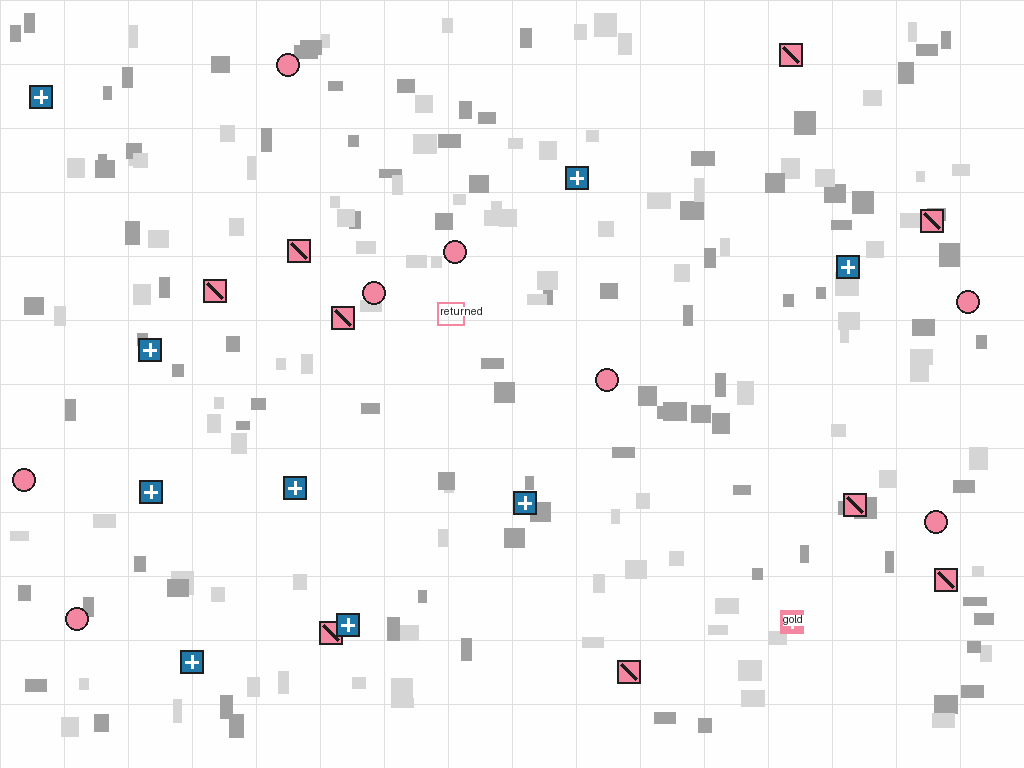

In [8]:
test_actions, test_reviews = ActionLog(), ReviewQueue()
for example, outcome in zip(test, hierarchy_outcomes, strict=True):
    helpers.record_outcome(example.id, outcome, test_actions, test_reviews)
print("Review notes:", json.dumps(test_reviews.to_dicts(), indent=2))
failed_index = next(
    (
        index
        for index, (outcome, label) in enumerate(zip(hierarchy_outcomes, test_labels, strict=True))
        if outcome.status == "localized" and not helpers.hit(outcome, label)
    ),
    None,
)
if failed_index is None:
    print("This run had no accepted wrong localization to overlay.")
else:
    failed_view = helpers.load_view(test[failed_index].fields)
    failure_label = test_labels[failed_index]
    print("Accepted wrong example:", test[failed_index].id, "gold:", failure_label["status"])
    overlays = {"returned": hierarchy_outcomes[failed_index].box}
    if failure_label["box"] is not None:
        overlays["gold"] = failure_label["box"]
    display(draw_boxes(failed_view.image, overlays))

## What was and was not measured

The committed run is **synthetic; not measured live**. Its 20 scored diagrams and 2 demonstration diagrams were drawn for this recipe. Answers were authored, including their mistakes. All metrics are pipeline checks, and they establish no Jev quality, speed, or cost advantage for tiling.

The input-token, output-token, latency, and cost fields below remain `null` because these quantities were not measured. Logical request counts are available; they must not be converted to guessed token or cost estimates. A live notebook run is diagnostic until recorded. Reportable model numbers require recorded held-out answers with the returned versioned model, capture date, and N. The README describes recording the same adaptive request triples; no recording has been made here.

In [9]:
measurement = {
    "mode": backend.mode,
    "scored_examples": len(scored),
    "validation_n": len(validation),
    "test_n": len(test),
    "demo_n": len(examples) - len(scored),
    "model": None if backend.mode in ("synthetic", "scripted") else backend.model,
    "capture_dates": list(getattr(backend, "recorded_dates", ())) or None,
    "input_tokens": None,
    "output_tokens": None,
    "latency_seconds": None,
    "cost_usd": None,
}
print(json.dumps(measurement, indent=2))
if backend.mode in ("synthetic", "scripted"):
    print("Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(validation)} validation; {len(test)} test; {len(examples) - len(scored)} demo.")
else:
    print(f"Mode: {backend.mode}; returned/requested model: {backend.model}")
    print(f"N: {len(validation)} validation; {len(test)} test; {len(examples) - len(scored)} demo.")

{
  "mode": "synthetic",
  "scored_examples": 20,
  "validation_n": 10,
  "test_n": 10,
  "demo_n": 2,
  "model": null,
  "capture_dates": null,
  "input_tokens": null,
  "output_tokens": null,
  "latency_seconds": null,
  "cost_usd": null
}
Not measured live: a pipeline check, not a Jev result.
N: 10 validation; 10 test; 2 demo.


## Next steps

Try a different target size, an additional distractor shape, or a stricter rectangle gate on a new validation split. To add another level, first define valid image sizes and a new request budget; the current code deliberately refuses depth above two. Increasing overlap can preserve seam-crossing objects while spending more image area, but only recorded data can establish an inference tradeoff.

Compare the staged decision pattern with [40 · Hierarchical classification](../40-hierarchical-classification/notebook.ipynb), the bounded retrieval pattern with [46 · Semantic context paging](../46-semantic-context-paging/notebook.ipynb), and the narrow follow-up design with [39 · Document extraction cascade](../39-document-extraction-cascade/notebook.ipynb). See the repository's [offline/live rules](../../docs/offline-and-live.md) before reporting model measurements.